# Chapter 4: Building Models with Distance Metrics and Nearest Neighbors

This notebook covers Chapter 4 of *scikit-learn Cookbook* (3rd Edition, Packt). Many machine learning methods are based on a simple idea: **similar inputs should have similar outputs**. To use this idea, we need a way to measure similarity, which is done with **distance metrics**. This chapter covers:
- Common distance metrics
- K-Nearest Neighbors (KNN) for classification
- The importance of feature scaling
- Choosing $k$ and weighting neighbors
- KNN for regression
- Efficient neighbor search with KD-trees and Ball trees
- Unsupervised neighbor search with `NearestNeighbors`

In [4]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine, load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.metrics import pairwise_distances, mean_squared_error, r2_score
from sklearn.neighbors import (KNeighborsClassifier, KNeighborsRegressor,
                               NearestNeighbors, NearestCentroid)

## 1. Distance Metrics

A distance metric $d(\mathbf{x}, \mathbf{z})$ measures how far apart two points are. The most common ones:

- **Euclidean (L2)**: straight-line distance, $d = \sqrt{\sum_j (x_j - z_j)^2}$
- **Manhattan (L1)**: sum of absolute differences, $d = \sum_j |x_j - z_j|$, like walking along city blocks
- **Minkowski**: the general form $d = \left(\sum_j |x_j - z_j|^p\right)^{1/p}$; $p=1$ is Manhattan and $p=2$ is Euclidean
- **Chebyshev**: the largest single difference, $d = \max_j |x_j - z_j|$
- **Cosine distance**: $1 - \cos\theta = 1 - \frac{\mathbf{x} \cdot \mathbf{z}}{\|\mathbf{x}\|\|\mathbf{z}\|}$, which compares direction rather than size (common for text)

The choice of metric changes which points count as "near".

In [5]:
points = np.array([[0, 0], [3, 4], [6, 8], [1, 7]])
labels = ['A', 'B', 'C', 'D']

for metric in ['euclidean', 'manhattan', 'chebyshev', 'cosine']:
    D = pairwise_distances(points, metric=metric)
    print(f'\n{metric} distances:')
    print(pd.DataFrame(D.round(3), index=labels, columns=labels))


euclidean distances:
        A      B       C      D
A   0.000  5.000  10.000  7.071
B   5.000  0.000   5.000  3.606
C  10.000  5.000   0.000  5.099
D   7.071  3.606   5.099  0.000

manhattan distances:
      A    B     C    D
A   0.0  7.0  14.0  8.0
B   7.0  0.0   7.0  5.0
C  14.0  7.0   0.0  6.0
D   8.0  5.0   6.0  0.0

chebyshev distances:
     A    B    C    D
A  0.0  4.0  8.0  7.0
B  4.0  0.0  4.0  3.0
C  8.0  4.0  0.0  5.0
D  7.0  3.0  5.0  0.0

cosine distances:
     A      B      C      D
A  0.0  1.000  1.000  1.000
B  1.0  0.000  0.000  0.123
C  1.0  0.000  0.000  0.123
D  1.0  0.123  0.123  0.000


The distance from A to B is 5 with Euclidean, 7 with Manhattan, and 4 with Chebyshev, so each metric has a different notion of "far". With cosine distance, B and C have distance 0 because they point in exactly the same direction ([6, 8] is just [3, 4] doubled), even though they are far apart in Euclidean terms.

## 2. K-Nearest Neighbors Classification

**KNN** is a "lazy" learner: `fit()` simply stores the training data. To classify a new point, it:
1. Computes the distance from the point to all training samples.
2. Finds the $k$ nearest neighbors.
3. Predicts the **majority class** among those neighbors.

KNN makes no assumptions about the shape of the decision boundary, which makes it flexible, but prediction becomes slow on large datasets.

The **wine** dataset (178 wines, 13 chemical features, 3 cultivars) is used.

In [6]:
wine = load_wine()
X, y = wine.data, wine.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

pd.DataFrame(X, columns=wine.feature_names).describe().loc[['mean', 'std', 'max']].round(2)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


The features are on very different scales: `proline` reaches values above 1,000, while others such as `hue` stay around 1. This matters a lot for distance-based models.

## 3. Why Scaling Matters for Distance-Based Models

Because KNN uses distances, features with large values dominate the calculation. Without scaling, the wine model would essentially look only at `proline`.

In [7]:
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
knn_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_scaled.fit(X_train, y_train)

print(f'KNN without scaling: test accuracy = {knn_raw.score(X_test, y_test):.3f}')
print(f'KNN with scaling:    test accuracy = {knn_scaled.score(X_test, y_test):.3f}')

KNN without scaling: test accuracy = 0.778
KNN with scaling:    test accuracy = 0.933


In [8]:
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
knn_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_scaled.fit(X_train, y_train)

print(f'KNN without scaling: test accuracy = {knn_raw.score(X_test, y_test):.3f}')
print(f'KNN with scaling:    test accuracy = {knn_scaled.score(X_test, y_test):.3f}')

KNN without scaling: test accuracy = 0.778
KNN with scaling:    test accuracy = 0.933


Scaling improves accuracy dramatically. After standardization every feature contributes fairly to the distance, so the model can use all 13 chemical properties instead of being dominated by one.

## 4. Choosing $k$ and Weighting Neighbors

- **Small $k$** (e.g., 1): very flexible, follows noise, high variance (overfitting).
- **Large $k$**: smoother decisions, but may ignore local patterns (underfitting).

$k$ is chosen with **cross-validation**. Another option is `weights='distance'`, which gives closer neighbors more influence (weight $= 1/d$) instead of counting all $k$ neighbors equally.

Best k by cross-validation: 15


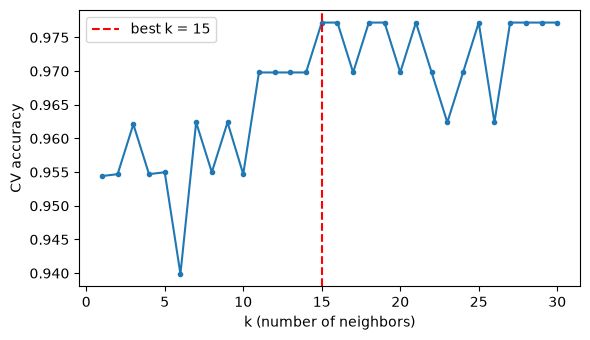

In [11]:
k_values = range(1, 31)
cv_scores = [cross_val_score(make_pipeline(StandardScaler(),
                                           KNeighborsClassifier(n_neighbors=k)),
                             X_train, y_train, cv=5).mean()
             for k in k_values]

best_k = k_values[int(np.argmax(cv_scores))]
print('Best k by cross-validation:', best_k)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(k_values, cv_scores, marker='.')
ax.axvline(best_k, color='red', linestyle='--', label=f'best k = {best_k}')
ax.set_xlabel('k (number of neighbors)')
ax.set_ylabel('CV accuracy')
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])
param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan'],
}
grid = GridSearchCV(pipe, param_grid, cv=5).fit(X_train, y_train)

print('Best parameters:', grid.best_params_)
print(f'Best CV accuracy: {grid.best_score_:.3f}')
print(f'Test accuracy:    {grid.score(X_test, y_test):.3f}')

Best parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 15, 'knn__weights': 'uniform'}
Best CV accuracy: 0.977
Test accuracy:    1.000


Cross-validation accuracy changes with $k$: very small values are unstable, and very large values start to blur the class boundaries. The grid search tunes $k$, the weighting scheme, and the distance metric together, showing that the metric itself is a hyperparameter worth tuning.

### 4.1 A Simple Alternative: Nearest Centroid

`NearestCentroid` computes the mean point (centroid) of each class and assigns new points to the closest centroid. It is extremely fast and works well when classes form compact groups.

In [13]:
nc = make_pipeline(StandardScaler(), NearestCentroid()).fit(X_train, y_train)
print(f'Nearest centroid test accuracy: {nc.score(X_test, y_test):.3f}')

Nearest centroid test accuracy: 0.978


## 5. KNN Regression

For regression, KNN predicts the **average target value** of the $k$ nearest neighbors (or a distance-weighted average):

$$\hat{y} = \frac{1}{k} \sum_{i \in N_k(\mathbf{x})} y_i$$

The example predicts disease progression in the **diabetes** dataset (442 patients, 10 features).

In [15]:
diab = load_diabetes()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(diab.data, diab.target,
                                              test_size=0.25, random_state=42)

for k in [1, 5, 15, 30]:
    reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    reg.fit(Xd_tr, yd_tr)
    pred = reg.predict(Xd_te)
    rmse = mean_squared_error(yd_te, pred) ** 0.5
    print(f'k={k:>2}: test RMSE = {rmse:6.2f}, R2 = {r2_score(yd_te, pred):.3f}')

k= 1: test RMSE =  76.23, R2 = -0.051
k= 5: test RMSE =  56.08, R2 = 0.431
k=15: test RMSE =  54.79, R2 = 0.457
k=30: test RMSE =  54.43, R2 = 0.464


With $k=1$ the model copies the single nearest patient, which is noisy and gives the worst error. Increasing $k$ averages over more patients and improves the predictions, until averaging over too many patients starts to smooth away useful detail. This is the same bias-variance trade-off seen in classification.

## 6. Efficient Neighbor Search: KD-Trees and Ball Trees

The naive approach (**brute force**) computes the distance to every training point, which costs $O(n)$ per query. scikit-learn can build tree structures that skip most of the comparisons:
- **KD-tree**: recursively splits the space along one feature at a time. Very fast in low dimensions, but less efficient as the number of features grows.
- **Ball tree**: groups points into nested hyperspheres ("balls"). Handles higher dimensions and more distance metrics better than a KD-tree.
- **auto**: scikit-learn chooses the method based on the data.

All methods return the **same neighbors**; only the speed differs.

In [16]:
rng = np.random.default_rng(0)
X_big = rng.normal(size=(20000, 5))
queries = rng.normal(size=(2000, 5))

for algo in ['brute', 'kd_tree', 'ball_tree']:
    nn = NearestNeighbors(n_neighbors=5, algorithm=algo).fit(X_big)
    start = time.perf_counter()
    dist, idx = nn.kneighbors(queries)
    elapsed = time.perf_counter() - start
    print(f'{algo:>9}: {elapsed:.3f} s, first neighbors of query 0 = {idx[0]}')

    brute: 0.180 s, first neighbors of query 0 = [ 2156 14361 13269  6498 17348]
  kd_tree: 0.052 s, first neighbors of query 0 = [ 2156 14361 13269  6498 17348]
ball_tree: 0.208 s, first neighbors of query 0 = [ 2156 14361 13269  6498 17348]


All three algorithms return identical neighbors, confirming that they are exact methods. The timing differences depend on the data size and number of dimensions; for low-dimensional data such as this, the tree-based methods usually avoid many distance computations compared to brute force.

## 7. Unsupervised Neighbor Search

`NearestNeighbors` can be used without any labels, for example to find similar items (recommendations), detect points far from all others (possible outliers), or find all points within a radius.

In [17]:
X_wine_std = StandardScaler().fit_transform(X)
nn = NearestNeighbors(n_neighbors=4).fit(X_wine_std)

dist, idx = nn.kneighbors(X_wine_std[:1])
print('Wines most similar to wine 0:', idx[0][1:])
print('Their distances:', dist[0][1:].round(3))
print('Their classes:', y[idx[0][1:]], ' (wine 0 class:', y[0], ')')

radius_idx = nn.radius_neighbors(X_wine_std[:1], radius=2.5, return_distance=False)[0]
print('\nNumber of wines within radius 2.5 of wine 0:', len(radius_idx))

Wines most similar to wine 0: [20 56 40]
Their distances: [1.288 1.564 1.88 ]
Their classes: [0 0 0]  (wine 0 class: 0 )

Number of wines within radius 2.5 of wine 0: 9


The wines most similar to wine 0 belong to the same cultivar, even though no labels were used in the search. This shows why nearest-neighbor search is useful for similarity-based tasks such as recommendation systems and anomaly detection.

## Chapter Summary

- **Distance metrics** (Euclidean, Manhattan, Minkowski, Chebyshev, cosine) define what "similar" means, and the choice affects the results.
- **KNN classification** predicts the majority class of the $k$ nearest training points; **KNN regression** predicts their average target.
- Distance-based models **require feature scaling**, otherwise features with large values dominate.
- $k$ controls the bias-variance trade-off and should be chosen with cross-validation, along with the weighting scheme and distance metric.
- **NearestCentroid** is a fast alternative that compares points to class means.
- **KD-trees** and **Ball trees** speed up exact neighbor search compared to brute force, especially in low dimensions.
- **NearestNeighbors** supports unsupervised tasks such as finding similar items and radius searches.